# Rate and distortion from 1000× to 100×

The appendix on the rate-distortion sweep (Tables 10-14) and the main text's Figure 3.

The budgets are GyroSplat's stored values at eight sizes (4 bytes each). The Fourier codes were re-run at exactly these bytes, with the position of every kept coefficient counted. The other sweeps (field-only splats and neural field, wavelets, PCA, ZFP, SZ3) use the same value counts, so the wavelets sit at half the compression ratio by bytes. The neural fields of the sweep are widened with the budget, so their 302× and 142× points can differ slightly from Table 1. Seeded methods: seeds 0-2, mean ± standard deviation of the snapshot median.

In [1]:
import pathlib
import sys

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

REPO = pathlib.Path.cwd()
while not (REPO / "neugk").exists():  # the repository root
    REPO = REPO.parent
sys.path.insert(0, str(REPO))
RESULTS = REPO / "neugk/gyrosplat/results"
CONFIGS = REPO / "configs/gyrosplat"

from neugk.gyrosplat.eval.paper import experiments as X
from neugk.gyrosplat.eval.paper import load_experiments, load_rows

rows = load_rows(RESULTS / "rows/gkw_rows.jsonl")
exp = load_experiments(RESULTS / "experiments")
FIGURES = RESULTS / "figures"
FIGURES.mkdir(exist_ok=True)

from neugk.gyrosplat.eval.paper.figures import rd_figure

## The budgets (Table 14)

In [2]:
display(Markdown(X.rd_budget_table(exp)))

| nominal CR | payload bytes | CR from bytes |
|---|---|---|
| 1000× | 89,188 | 999.3 |
| 800× | 111,380 | 800.2 |
| 600× | 148,568 | 599.9 |
| 450× | 198,084 | 450.0 |
| 302× | 294,928 | 302.2 |
| 200× | 445,672 | 200.0 |
| 142× | 626,692 | 142.2 |
| 100× | 891,332 | 100.0 |

## Potential PSNR, flux error, distribution PSNR and cancellation ratio (Tables 10-13)

In [3]:
for key, title in (("psnr_phi", "potential PSNR (dB)"), ("flux_rel_l1", "heat-flux relL1"),
                   ("psnr_f", "distribution PSNR (dB)"), ("kappa_rel", "κ / κ_truth")):
    display(Markdown(f"**{title}**\n\n" + X.rd_table(exp, key)))

**potential PSNR (dB)**

| method | first budget | second budget |
|---|---|---|
| *Budgets 1000× / 800×* | | |
| GyroSplat | 22.24 ± 0.30 | 23.75 ± 0.20 |
| NF + physics | 23.01 ± 0.13 | 23.86 ± 0.10 |
| Fourier + refinement | 15.57 | 16.41 |
| Fourier top-K | 12.11 | 13.42 |
| *Budgets 600× / 450×* | | |
| GyroSplat | 25.14 ± 0.08 | 26.36 ± 0.08 |
| NF + physics | 24.73 ± 0.03 | 25.38 ± 0.13 |
| Fourier + refinement | 19.35 | 21.25 |
| Fourier top-K | 15.71 | 18.75 |
| *Budgets 302× / 200×* | | |
| GyroSplat | 27.70 ± 0.06 | 28.80 ± 0.09 |
| NF + physics | 26.57 ± 0.12 | 27.37 ± 0.18 |
| Fourier + refinement | 23.19 | 24.67 |
| Fourier top-K | 21.36 | 23.63 |
| *Budgets 142× / 100×* | | |
| GyroSplat | 29.25 ± 0.08 | 29.53 ± 0.05 |
| NF + physics | 28.01 ± 0.12 | 28.19 ± 0.28 |
| Fourier + refinement | 25.98 | 27.49 |
| Fourier top-K | 24.89 | 26.73 |

**heat-flux relL1**

| method | first budget | second budget |
|---|---|---|
| *Budgets 1000× / 800×* | | |
| GyroSplat | 0.003 ± 0.001 | 9.0×10⁻⁴ ± 2.2×10⁻⁴ |
| NF + physics | 0.235 ± 3.9×10⁻⁴ | 0.216 ± 0.007 |
| Fourier + refinement | 0.089 | 0.073 |
| Fourier top-K | 0.552 | 0.492 |
| *Budgets 600× / 450×* | | |
| GyroSplat | 2.7×10⁻⁴ ± 9.9×10⁻⁵ | 1.5×10⁻⁵ ± 2.8×10⁻⁶ |
| NF + physics | 0.188 ± 0.004 | 0.169 ± 0.003 |
| Fourier + refinement | 0.054 | 0.039 |
| Fourier top-K | 0.443 | 0.375 |
| *Budgets 302× / 200×* | | |
| GyroSplat | 5.7×10⁻⁷ ± 2.6×10⁻⁷ | 7.0×10⁻⁸ ± 2.5×10⁻⁸ |
| NF + physics | 0.144 ± 0.002 | 0.118 ± 0.002 |
| Fourier + refinement | 0.024 | 0.013 |
| Fourier top-K | 0.289 | 0.212 |
| *Budgets 142× / 100×* | | |
| GyroSplat | 3.8×10⁻⁸ ± 2.3×10⁻⁹ | 2.6×10⁻⁸ ± 1.2×10⁻⁹ |
| NF + physics | 0.105 ± 0.002 | 0.097 ± 7.7×10⁻⁴ |
| Fourier + refinement | 0.008 | 0.002 |
| Fourier top-K | 0.149 | 0.105 |

**distribution PSNR (dB)**

| method | first budget | second budget |
|---|---|---|
| *Budgets 1000× / 800×* | | |
| GyroSplat | 35.77 ± 0.01 | 36.22 ± 0.03 |
| NF + physics | 35.44 ± 0.05 | 35.89 ± 0.04 |
| Fourier + refinement | 33.61 | 33.91 |
| Fourier top-K | 33.61 | 33.91 |
| *Budgets 600× / 450×* | | |
| GyroSplat | 36.80 ± 0.02 | 37.26 ± 0.02 |
| NF + physics | 36.38 ± 0.07 | 36.75 ± 0.04 |
| Fourier + refinement | 34.28 | 34.66 |
| Fourier top-K | 34.28 | 34.66 |
| *Budgets 302× / 200×* | | |
| GyroSplat | 37.62 ± 0.03 | 37.99 ± 0.01 |
| NF + physics | 37.28 ± 0.10 | 37.80 ± 0.02 |
| Fourier + refinement | 35.23 | 35.89 |
| Fourier top-K | 35.25 | 35.92 |
| *Budgets 142× / 100×* | | |
| GyroSplat | 38.20 ± 0.00 | 38.30 ± 0.01 |
| NF + physics | 38.24 ± 0.16 | 38.63 ± 0.13 |
| Fourier + refinement | 36.57 | 37.28 |
| Fourier top-K | 36.57 | 37.32 |

**κ / κ_truth**

| method | first budget | second budget |
|---|---|---|
| *Budgets 1000× / 800×* | | |
| GyroSplat | 1.165 ± 0.024 | 1.091 ± 0.013 |
| NF + physics | 0.854 ± 0.005 | 0.860 ± 0.005 |
| Fourier + refinement | 4.003 | 3.832 |
| Fourier top-K | 7.846 | 7.060 |
| *Budgets 600× / 450×* | | |
| GyroSplat | 1.045 ± 0.011 | 1.006 ± 0.010 |
| NF + physics | 0.863 ± 0.003 | 0.874 ± 7.5×10⁻⁴ |
| Fourier + refinement | 3.679 | 3.414 |
| Fourier top-K | 6.065 | 5.150 |
| *Budgets 302× / 200×* | | |
| GyroSplat | 0.986 ± 0.004 | 0.970 ± 0.004 |
| NF + physics | 0.884 ± 0.001 | 0.892 ± 8.4×10⁻⁴ |
| Fourier + refinement | 3.194 | 2.932 |
| Fourier top-K | 4.290 | 3.663 |
| *Budgets 142× / 100×* | | |
| GyroSplat | 0.973 ± 0.003 | 0.990 ± 0.003 |
| NF + physics | 0.898 ± 0.004 | 0.902 ± 0.002 |
| Fourier + refinement | 2.719 | 2.590 |
| Fourier top-K | 3.181 | 2.837 |

Which method has the highest potential PSNR at each budget:

In [4]:
for b in X.RD_BUDGETS:
    v = {m: X.rd_summary(exp, m, b, "psnr_phi")["value"] for m in X.RD_METHODS}
    best = max(v, key=v.get)
    print(f"{b:>5}x: {X.SHORT[best]:<22} {v[best]:6.2f} dB   (GyroSplat {v['gyrosplat']:.2f}, NF + physics "
          f"{v['neural_field_physics']:.2f})")

 1000x: NF + physics            23.01 dB   (GyroSplat 22.24, NF + physics 23.01)
  800x: NF + physics            23.86 dB   (GyroSplat 23.75, NF + physics 23.86)
  600x: GyroSplat               25.14 dB   (GyroSplat 25.14, NF + physics 24.73)
  450x: GyroSplat               26.36 dB   (GyroSplat 26.36, NF + physics 25.38)
  302x: GyroSplat               27.70 dB   (GyroSplat 27.70, NF + physics 26.57)
  200x: GyroSplat               28.80 dB   (GyroSplat 28.80, NF + physics 27.37)
  142x: GyroSplat               29.25 dB   (GyroSplat 29.25, NF + physics 28.01)
  100x: GyroSplat               29.53 dB   (GyroSplat 29.53, NF + physics 28.19)


## The figures

The curves of the main text, then every swept method with the codes evaluated at the two comparison budgets only as points (AE, VAE, VQ-VAE, Haar + refinement, db4).

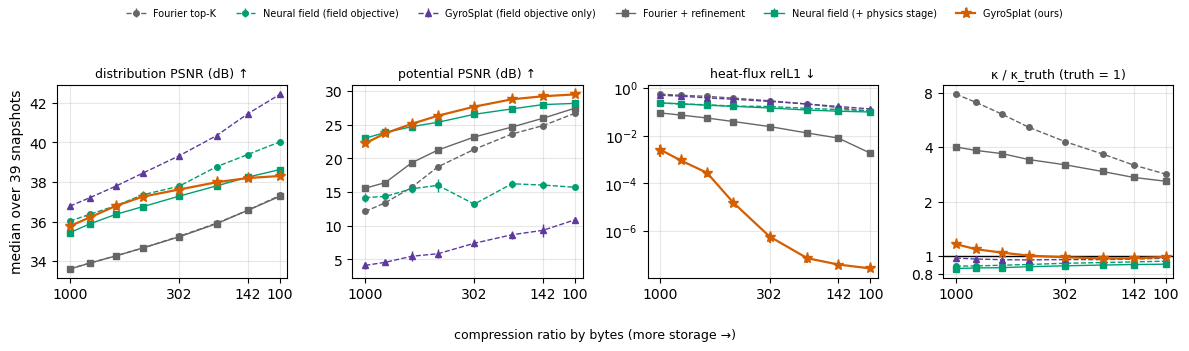

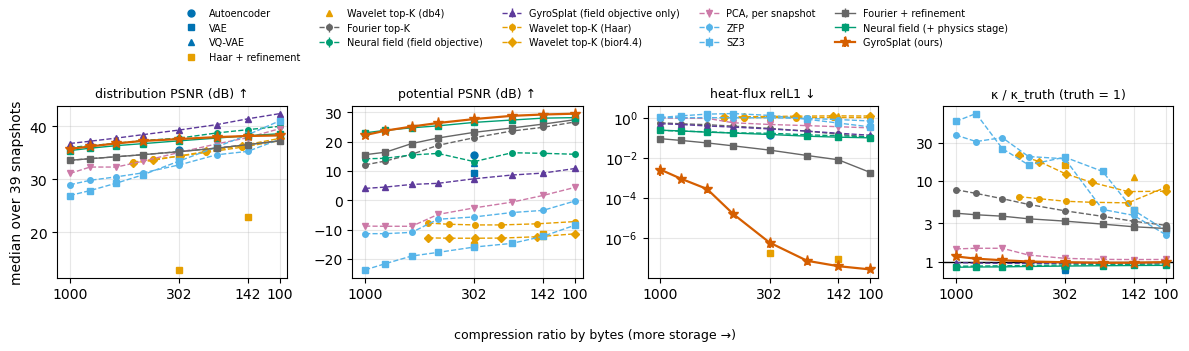

In [5]:
fig = rd_figure(exp)
plt.show()
fig = rd_figure(exp, rows, full=True)
fig.savefig(FIGURES / "rate_distortion_all.pdf", bbox_inches="tight")
plt.show()